## Dataset Overview: Car Price Prediction
**MCC Machine Learning Track — Week 3: Regression Task**

This dataset contains **1,000 records** of vehicles designed for regression modeling. The goal is to predict a car's **`Price`** based on its specifications, age, usage, and configuration.

### Features Description
| Feature | Data Type | Role | Description |
| :--- | :--- | :--- | :--- |
| **`Make`** | Categorical | Feature | Manufacturer brand of the car (`Honda`, `Ford`, `BMW`, `Audi`, `Toyota`) |
| **`Model`** | Categorical | Feature | Specific model designation (`Model A`, `Model B`, `Model C`, `Model D`, `Model E`) |
| **`Year`** | Numerical | Feature | Manufacturing year of the vehicle |
| **`Engine Size`** | Numerical | Feature | Engine displacement volume (in liters) |
| **`Mileage`** | Numerical | Feature | Total distance driven by the vehicle |
| **`Fuel Type`** | Categorical | Feature | Type of fuel used (`Petrol`, `Diesel`, `Electric`) |
| **`Transmission`** | Categorical | Feature | Gearbox type (`Manual`, `Automatic`) |
| **`Price`** | Numerical | **Target ($y$)** | Market price of the car |

# 1. Data Understanding

1. Import the necessary libraries for data analysis, visualization, preprocessing, and regression modeling.
2. Load the `Car_Price_Prediction.csv` dataset and preview a random sample of rows.
3. Inspect all column names and check the overall shape of the dataset.
4. Check the data types and general information of all columns.
5. Check for any missing (null) values in the dataset.
6. Check for any duplicate rows in the dataset.
7. Generate a statistical summary for the numerical features (`Year`, `Engine Size`, `Mileage`, `Price`).
8. Generate a statistical summary for the categorical features (`Make`, `Model`, `Fuel Type`, `Transmission`).
9. Explore the car categories: identify all unique car brands (`Make`), models (`Model`), fuel types (`Fuel Type`), and transmissions (`Transmission`), and check how many cars belong to each category.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Car_Price_Prediction.csv')
display(df.sample(5))

display(df.columns.tolist())
display(df.shape)

df.info()

display(df.isnull().sum())
display(df.duplicated().sum())

display(df.describe())
display(df.describe(include=['object', 'category']))


display(df['Make'].value_counts())
display(df['Model'].value_counts())
display(df['Fuel Type'].value_counts())
display(df['Transmission'].value_counts())

,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
820,Ford,Model E,2015,3.9,193295,Petrol,Automatic,24035.944449
130,Honda,Model E,2005,3.2,86332,Petrol,Automatic,23282.895952
774,Toyota,Model D,2004,1.9,135902,Electric,Automatic,20423.192572
143,Honda,Model B,2008,1.2,7971,Diesel,Manual,25789.707792
116,Ford,Model A,2012,2.4,194051,Petrol,Automatic,17320.429502


['Make',
 'Model',
 'Year',
 'Engine Size',
 'Mileage',
 'Fuel Type',
 'Transmission',
 'Price']

(1000, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Make          1000 non-null   object 
 1   Model         1000 non-null   object 
 2   Year          1000 non-null   int64  
 3   Engine Size   1000 non-null   float64
 4   Mileage       1000 non-null   int64  
 5   Fuel Type     1000 non-null   object 
 6   Transmission  1000 non-null   object 
 7   Price         1000 non-null   float64
dtypes: float64(2), int64(2), object(4)
memory usage: 62.6+ KB


Make            0
Model           0
Year            0
Engine Size     0
Mileage         0
Fuel Type       0
Transmission    0
Price           0
dtype: int64

0

... (2 outputs left out)

Make
Ford      225
Audi      212
Honda     198
Toyota    187
BMW       178
Name: count, dtype: int64

Model
Model B    212
Model C    205
Model A    202
Model D    197
Model E    184
Name: count, dtype: int64

Fuel Type
Diesel      344
Petrol      331
Electric    325
Name: count, dtype: int64

Transmission
Manual       511
Automatic    489
Name: count, dtype: int64

# 2. EDA and Feature Engineering

1. Search for any potential **outliers** across the numerical features (`Year`, `Engine Size`, `Mileage`, `Price`).
2. Investigate the **distribution** of each numerical feature.
3. Explore the relationship between each numerical feature and the target variable (**`Price`**).
4. Check the **frequency distribution** of each categorical feature (`Make`, `Model`, `Fuel Type`, `Transmission`) to see the count of cars in each category.
5. Investigate how the car **`Price`** varies across different car makes, models, fuel types, and transmission types.
6. Examine the **correlation** between all numerical features and **`Price`**.
7. **Feature Engineering:** Before preprocessing and splitting the data, explore whether you can create any useful new features from the existing columns (e.g., using `Year` or `Mileage`).

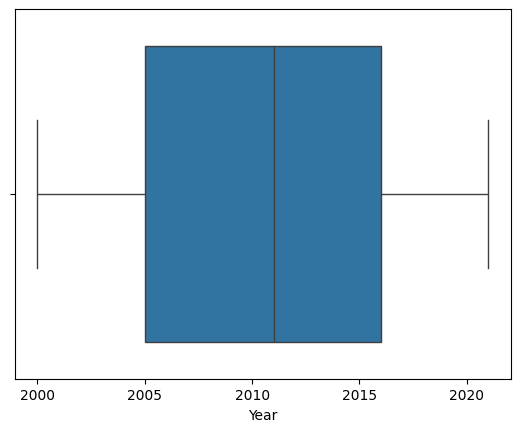

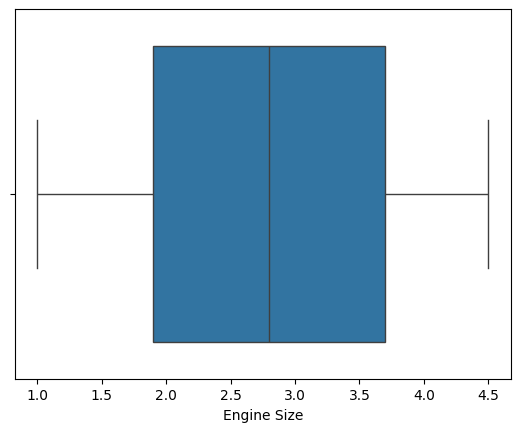

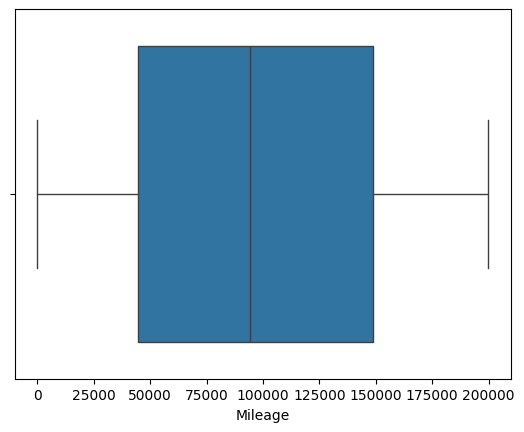

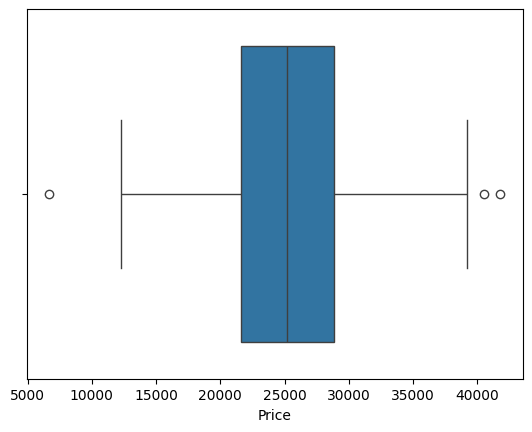

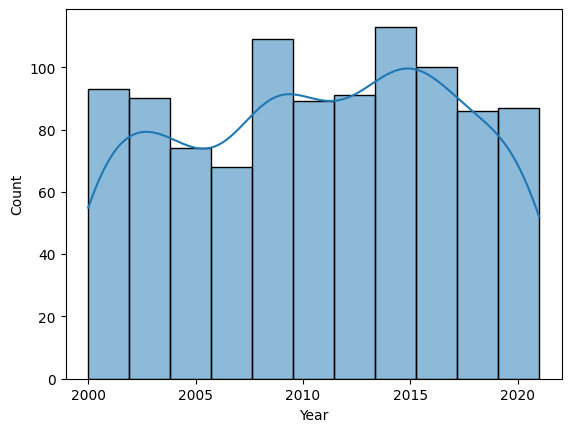

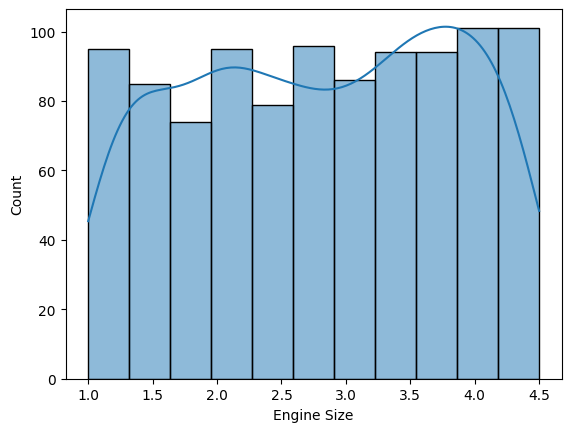

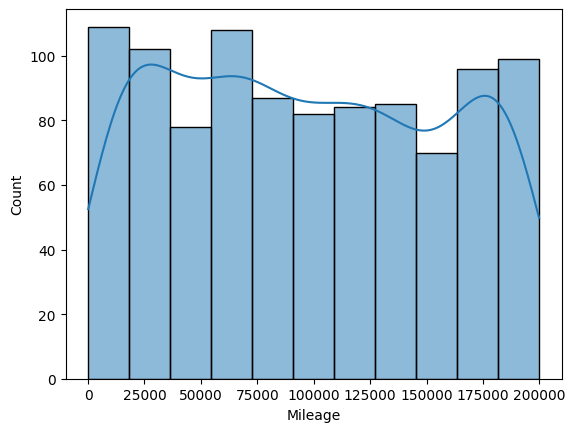

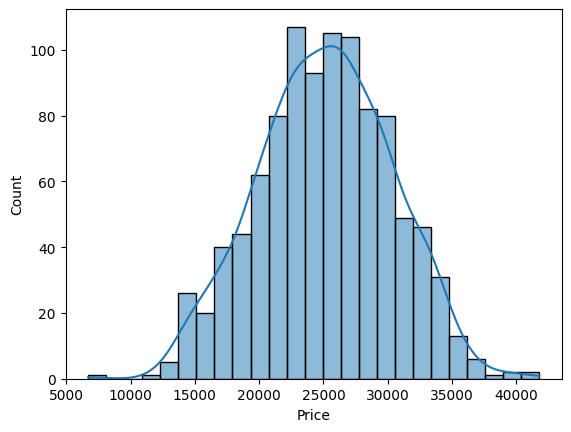

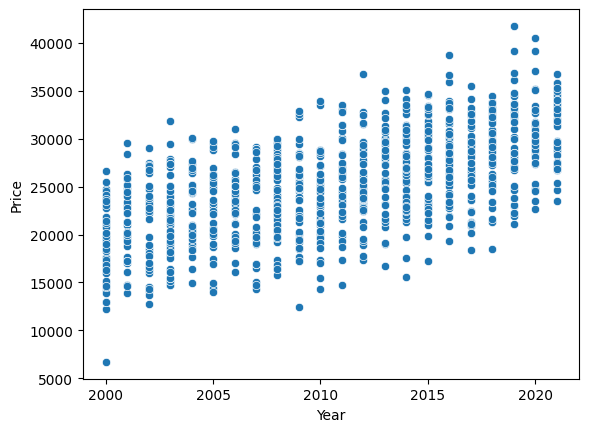

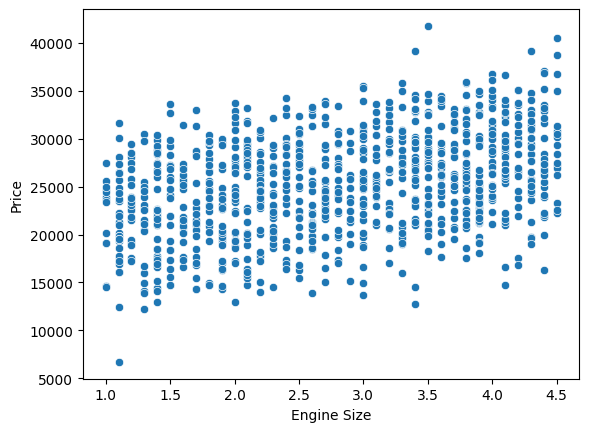

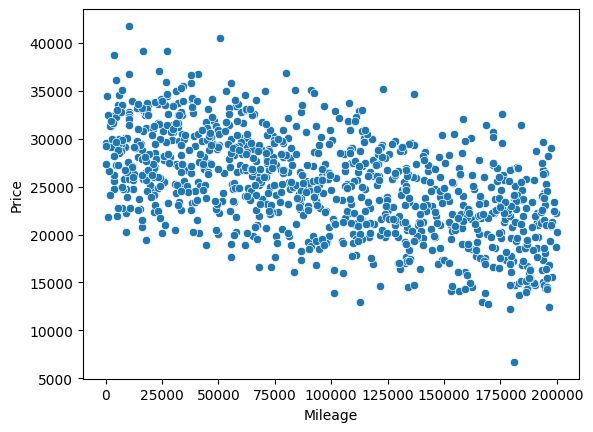

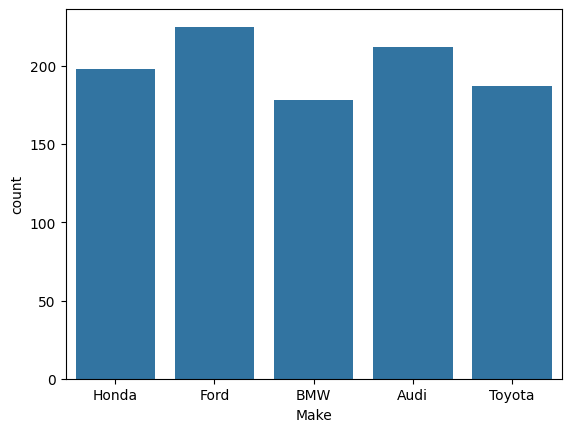

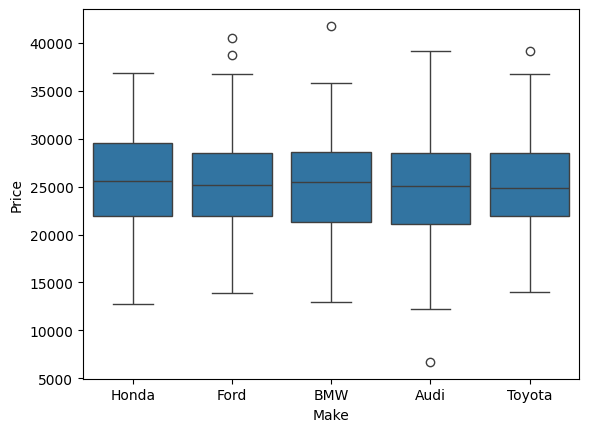

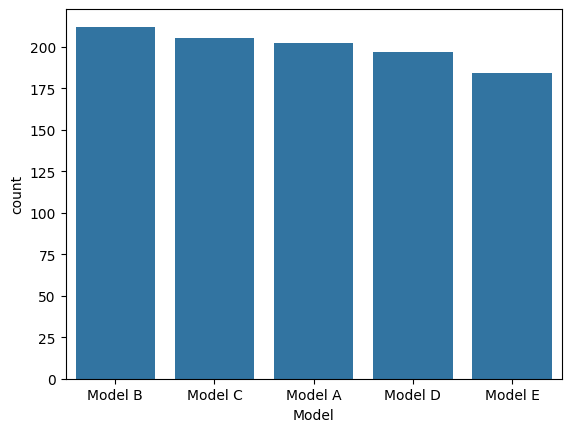

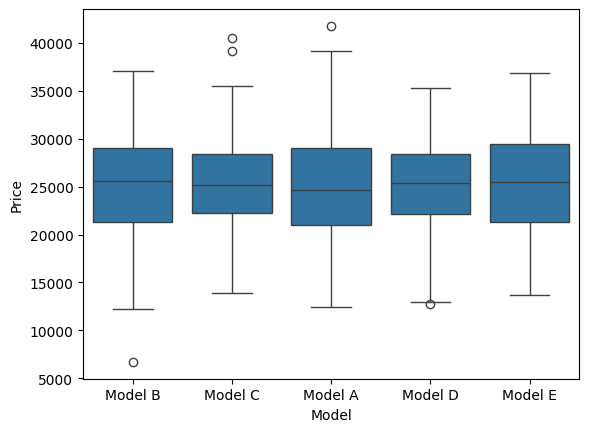

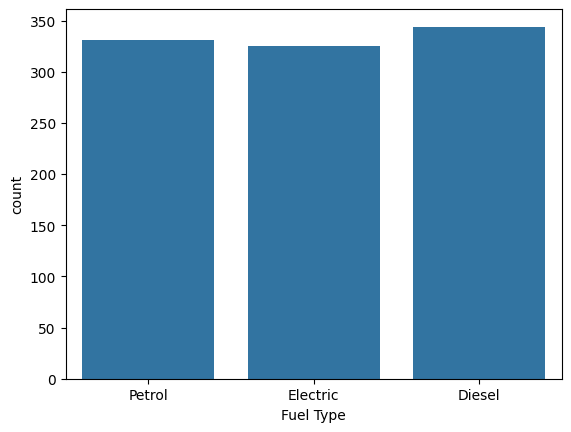

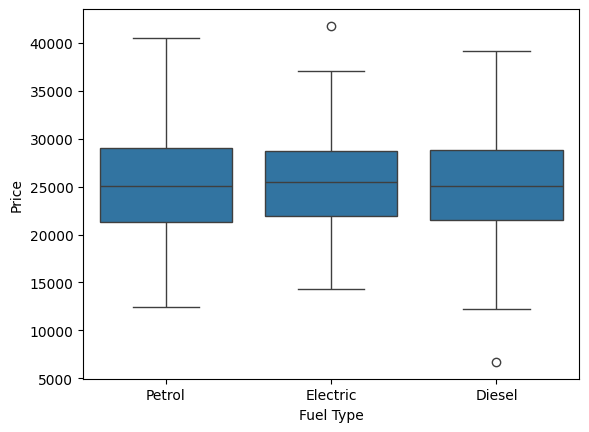

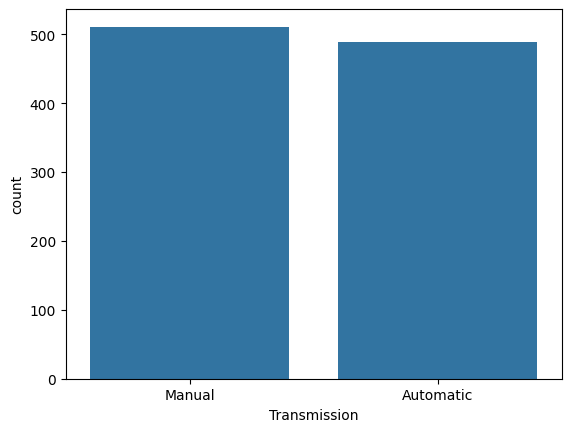

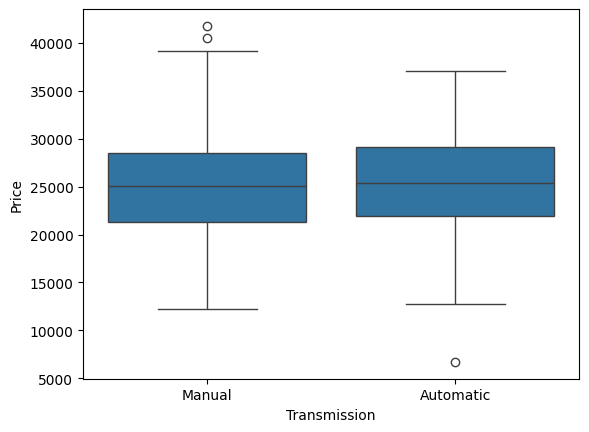

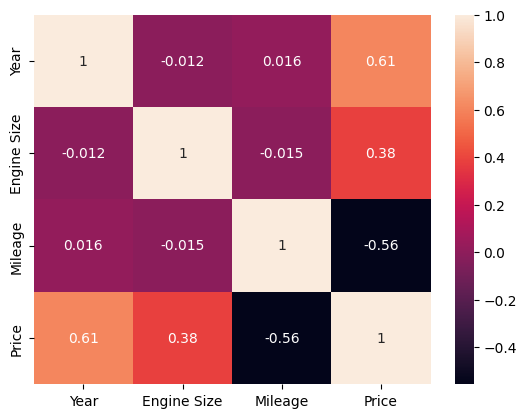

In [3]:
my_num_cols = ['Year', 'Engine Size', 'Mileage', 'Price']
my_cat_cols = ['Make', 'Model', 'Fuel Type', 'Transmission']

for col in my_num_cols:
    sns.boxplot(x=df[col])
    plt.show()

for col in my_num_cols:
    sns.histplot(df[col], kde=True)
    plt.show()

sns.scatterplot(x=df['Year'], y=df['Price'])
plt.show()

sns.scatterplot(x=df['Engine Size'], y=df['Price'])
plt.show()

sns.scatterplot(x=df['Mileage'], y=df['Price'])
plt.show()

for col in my_cat_cols:
    sns.countplot(x=df[col])
    plt.show()
    
    sns.boxplot(x=df[col], y=df['Price'])
    plt.show()

sns.heatmap(df[['Year', 'Engine Size', 'Mileage', 'Price']].corr(), annot=True)
plt.show()

df['Car_Age'] = 2026 - df['Year']
df.drop('Year', axis=1, inplace=True)

# 3. Preprocessing

1. Separate the features ($X$) and the target variable ($y$ — `Price`), then split the dataset into training and testing sets.
2. Encode the categorical features (`Make`, `Model`, `Fuel Type`, `Transmission`) into numerical values.
3. Scale the numerical features.
4. Apply any additional preprocessing steps if needed.

> **Hints:**
> - In scaling, there is a scaler called **`StandardScaler`** that you can use if you have outliers in the data.
> - Take care and watch out for **Data Leakage**!

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df_encoded = pd.get_dummies(df, columns=['Make', 'Model', 'Fuel Type', 'Transmission'], drop_first=True)

X = df_encoded.drop('Price', axis=1)
y = df_encoded['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
cols_to_scale = ['Engine Size', 'Mileage', 'Car_Age']

X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

display(X_train.head())

,Engine Size,Mileage,Car_Age,Make_BMW,Make_Ford,Make_Honda,Make_Toyota,Model_Model B,Model_Model C,Model_Model D,Model_Model E,Fuel Type_Electric,Fuel Type_Petrol,Transmission_Manual
29,0.089052,-1.378616,1.582024,False,False,True,False,True,False,False,False,True,False,False
535,-0.685311,1.549909,0.617375,False,False,False,False,False,False,False,True,True,False,False
695,0.089052,1.240727,-0.186499,False,False,False,False,False,True,False,False,True,False,False
557,-1.556469,-0.829569,1.099700,True,False,False,False,False,False,True,False,False,False,False
836,0.960210,0.941258,-1.472697,False,True,False,False,False,False,False,True,True,False,True


# 4. Modeling

1. Train a **Linear Regression** model on the training data.
2. Evaluate the **Linear Regression** model on the **training set** using **MSE**, **MAE**, and **$R^2$ Score**.
3. Evaluate the **Linear Regression** model on the **testing set** using **MSE**, **MAE**, and **$R^2$ Score**.
4. Train an **SGDRegressor** model on the training data.
5. Evaluate the **SGDRegressor** model on the **training set** using **MSE**, **MAE**, and **$R^2$ Score**.
6. Evaluate the **SGDRegressor** model on the **testing set** using **MSE**, **MAE**, and **$R^2$ Score**.

In [5]:
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_train_pred_lr = lr_model.predict(X_train)
y_test_pred_lr = lr_model.predict(X_test)

display(mean_squared_error(y_train, y_train_pred_lr))
display(mean_absolute_error(y_train, y_train_pred_lr))
display(r2_score(y_train, y_train_pred_lr))

display(mean_squared_error(y_test, y_test_pred_lr))
display(mean_absolute_error(y_test, y_test_pred_lr))
display(r2_score(y_test, y_test_pred_lr))

sgd_model = SGDRegressor(random_state=42)
sgd_model.fit(X_train, y_train)

y_train_pred_sgd = sgd_model.predict(X_train)
y_test_pred_sgd = sgd_model.predict(X_test)

display(mean_squared_error(y_train, y_train_pred_sgd))
display(mean_absolute_error(y_train, y_train_pred_sgd))
display(r2_score(y_train, y_train_pred_sgd))

display(mean_squared_error(y_test, y_test_pred_sgd))
display(mean_absolute_error(y_test, y_test_pred_sgd))
display(r2_score(y_test, y_test_pred_sgd))

4115417.8836356183

1599.7171726741974

0.8457634186792121

5005471.209262069

1810.5547575776332

0.8170961815663225

... (2 outputs left out)

0.8454697348578979

4978870.647671211

1803.7246169335835

0.8180681868149883